# GB Electricity Demand: Exploratory Data Analysis (EDA)

**Data:** NESO historic demand data, 2018–2023. One row = one half-hour. All values are in MW.

**Project aim:** find half-hours (and days) when national demand (ND) is unusually high or low for that time of day, day of week and season.

**Steps in this notebook**
1. Load the six yearly files and merge them into one table
2. Univariate analysis: look at each column on its own
3. Bivariate analysis: look at how other columns relate to ND
4. Time-series checks: autocorrelation and one normal week
5. EDA summary: what was found, and what will be used for modelling

## 1. Load and merge the data

In [95]:
# Libraries
import numpy as np
import pyarrow.parquet as pq
import pyarrow.csv as pv
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from statsmodels.graphics.tsaplots import plot_acf


In [2]:
# Read the six raw yearly CSV files (one file per year)
df_18 = df = pd.read_csv("../data/raw/demanddata_2018.csv")
df_19 = df = pd.read_csv("../data/raw/demanddata_2019.csv")
df_20 = df = pd.read_csv("../data/raw/demanddata_2020.csv")
df_21 = df = pd.read_csv("../data/raw/demanddata_2021.csv")
df_22 = df = pd.read_csv("../data/raw/demanddata_2022.csv")
df_23 = df = pd.read_csv("../data/raw/demanddata_2023.csv")

### Save each year as parquet
Parquet files are smaller and load much faster than CSV.

In [3]:
# Save each year as a parquet file
df_18.to_parquet("../data/demanddata_2018.parquet", engine="pyarrow", index=False)
df_19.to_parquet("../data/demanddata_2019.parquet", engine="pyarrow", index=False)
df_20.to_parquet("../data/demanddata_2020.parquet", engine="pyarrow", index=False)
df_21.to_parquet("../data/demanddata_2021.parquet", engine="pyarrow", index=False)
df_22.to_parquet("../data/demanddata_2022.parquet", engine="pyarrow", index=False)
df_23.to_parquet("../data/demanddata_2023.parquet", engine="pyarrow", index=False)

### Reload the parquet files

In [4]:
# Reload each year from parquet
df_18 = pd.read_parquet("../data/demanddata_2018.parquet", engine="pyarrow")
df_19 = pd.read_parquet("../data/demanddata_2019.parquet", engine="pyarrow")
df_20 = pd.read_parquet("../data/demanddata_2020.parquet", engine="pyarrow")
df_21 = pd.read_parquet("../data/demanddata_2021.parquet", engine="pyarrow")
df_22 = pd.read_parquet("../data/demanddata_2022.parquet", engine="pyarrow")
df_23 = pd.read_parquet("../data/demanddata_2023.parquet", engine="pyarrow")

### Check the columns match before merging
The files can only be stacked cleanly if they have the same columns.

In [5]:
# Compare every yearly file with every other one
# 1 = same columns in the same order, 0 = different
dfs = [df_18, df_19, df_20, df_21, df_22, df_23]
labels = [f"Dataset {i}" for i in range(18, 24)]

# Build the comparison grid
matrix_data = [
    [int(a.columns.equals(b.columns)) for b in dfs] for a in dfs
]

# Show it as a table
matrix_df = pd.DataFrame(matrix_data, index=labels, columns=labels)
print(matrix_df)

# Result: 2019-2022 all match. 2018 and 2023 are different from the rest.

            Dataset 18  Dataset 19  Dataset 20  Dataset 21  Dataset 22  \
Dataset 18           1           0           0           0           0   
Dataset 19           0           1           1           1           1   
Dataset 20           0           1           1           1           1   
Dataset 21           0           1           1           1           1   
Dataset 22           0           1           1           1           1   
Dataset 23           0           0           0           0           0   

            Dataset 23  
Dataset 18           0  
Dataset 19           0  
Dataset 20           0  
Dataset 21           0  
Dataset 22           0  
Dataset 23           1  


In [6]:
# Compare the 2018 and 2023 columns directly
df_18.columns.equals(df_23.columns)
df_18.columns
df_23.columns
# 2023 has every column. 2018 is missing some (see the next cell)

Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'SCOTTISH_TRANSFER', 'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW',
       'MOYLE_FLOW', 'EAST_WEST_FLOW', 'NEMO_FLOW', 'NSL_FLOW',
       'ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW'],
      dtype='str')

In [7]:
print(df_19.columns) # 2019-2022: no SCOTTISH_TRANSFER column
print(df_23.columns) # 2023: has every column
print(df_18.columns) # 2018: no SCOTTISH_TRANSFER, NSL_FLOW, ELECLINK_FLOW, VIKING_FLOW or GREENLINK_FLOW

Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW',
       'NEMO_FLOW', 'NSL_FLOW', 'ELECLINK_FLOW', 'VIKING_FLOW',
       'GREENLINK_FLOW'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'SCOTTISH_TRANSFER', 'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW',
       'MOYLE_FLOW', 'EAST_WEST_FLOW', 'NEMO_FLOW', 'NSL_FLOW',
       'ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'E

### Make every file have the same columns
- Add the missing columns to the older files, filled with blanks (NaN)
- Put the columns in the same order as the 2023 file
- Add a `df_source` column saying which file each row came from (a check; removed after merging)

In [8]:
# Put the six tables in a dictionary so they can be looped over
dfs_dict = {
    'df_18': df_18,
    'df_19': df_19,
    'df_20': df_20,
    'df_21': df_21,
    'df_22': df_22,
    'df_23': df_23
}
# Columns that some years don't have
missing_cols = ['SCOTTISH_TRANSFER', 'NSL_FLOW', 'ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW']
# Column order to use: the 2023 order, plus df_source at the end
target_order = list(df_23.columns) + ['df_source'] if 'df_source' not in df_23.columns else list(df_23.columns)

for name, df in dfs_dict.items():
    # 1. Add any missing column, filled with blanks
    for col in missing_cols:
        if col not in df.columns:
            df[col] = np.nan

    # 2. Record which file the rows came from
    df['df_source'] = name

    # 3. Put the columns in the 2023 order
    dfs_dict[name] = df.reindex(columns=target_order)

# Copy the fixed tables back into the original variable names
df_18, df_19, df_20, df_21, df_22, df_23 = dfs_dict.values()

In [9]:
# Note: this loop doesn't change anything, because the reordered copy isn't saved.
# It's harmless: pd.concat matches columns by name, so column order doesn't matter.
target_order = list(df_23.columns)

for i in dfs:
    i = i.reindex(columns = target_order)

In [10]:
# Print each file's columns to check them
for i in dfs:
    print(i.columns)

Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW',
       'NEMO_FLOW', 'SCOTTISH_TRANSFER', 'NSL_FLOW', 'ELECLINK_FLOW',
       'VIKING_FLOW', 'GREENLINK_FLOW', 'df_source'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW',
       'NEMO_FLOW', 'NSL_FLOW', 'ELECLINK_FLOW', 'VIKING_FLOW',
       'GREENLINK_FLOW', 'SCOTTISH_TRANSFER', 'df_source'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD',

In [11]:
# Stack the six years on top of each other into one table
df_merged = pd.concat([df_18, df_19, df_20, df_21, df_22, df_23], axis = 0, ignore_index = True)

In [12]:
# Remove the source column now the merge is done
df_merged.drop(columns = 'df_source', inplace = True)

In [13]:
# Save the merged table
df_merged.to_parquet("../data/df_merged.parquet", engine="pyarrow", index=False)

**Checkpoint:** the merged table is saved as `df_merged.parquet`. Start from the next cell to skip the steps above.

In [14]:
# Reload the merged table
df_merged = pd.read_parquet("../data/df_merged.parquet", engine="pyarrow")

In [15]:
# Make all column names lowercase
df_merged.columns = df_merged.columns.str.lower()
print(df_merged.columns)

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow'],
      dtype='str')


### Add year, month and day columns
Taken from the settlement date. Used for grouping and plotting later.

In [16]:
# Turn the date text into a real date, then pull out the year, month and day of the month
df_merged.settlement_date = pd.to_datetime(df_merged.settlement_date)
df_merged['year'] = df_merged.settlement_date.dt.year
df_merged['month'] = df_merged.settlement_date.dt.month
df_merged['day'] = df_merged.settlement_date.dt.day

C:\Users\jagmeet\AppData\Local\Temp\ipykernel_16148\2933782120.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_merged.settlement_date = pd.to_datetime(df_merged.settlement_date)


In [17]:
# Check the new columns are there
df_merged.columns

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day'],
      dtype='str')

In [18]:
# Save
df_merged.to_parquet("../data/df_merged.parquet", engine="pyarrow", index=False)

## 2. Univariate analysis (each column on its own)

Checks:
- Rows per year
- Rows per date (every date should have 48 half-hours)
- Every column plotted over time
- Summary stats (median, quartiles, percentiles) to check skew and spot impossible values
- Missing values: blank cells, and half-hours with no row at all
- Duplicates: two rows for the same date and period

In [19]:
# Reload the merged table
df_merged = pd.read_parquet("../data/df_merged.parquet", engine="pyarrow")

In [20]:
# List the columns
df_merged.columns

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day'],
      dtype='str')

In [21]:
# Count rows per year
records_per_year = df_merged.groupby(['year']).size().reset_index(name = 'count')
records_per_year # Every year has 17,520 rows (365 days x 48). 2020 has 48 more because it's a leap year (29 Feb)

,year,count
0,2018,17520
1,2019,17520
2,2020,17568
3,2021,17520
4,2022,17520
5,2023,17520


In [22]:
# Count rows per day of the MONTH (1-31), across all months and years
records_per_day = df_merged.groupby(['day']).size().reset_index(name = 'count')
records_per_day # Days 29-31 have fewer rows because not every month has them. Other small differences come from clock-change days. The proper per-date check is further down.

,day,count
0,1,3456
1,2,3456
2,3,3456
3,4,3456
4,5,3456
5,6,3456
6,7,3456
7,8,3456
8,9,3456
9,10,3456


In [23]:
# Check each column's data type
df_merged.dtypes

settlement_date              datetime64[us]
settlement_period                     int64
nd                                    int64
tsd                                   int64
england_wales_demand                  int64
embedded_wind_generation              int64
embedded_wind_capacity                int64
embedded_solar_generation             int64
embedded_solar_capacity               int64
non_bm_stor                           int64
pump_storage_pumping                  int64
scottish_transfer                   float64
ifa_flow                              int64
ifa2_flow                             int64
britned_flow                          int64
moyle_flow                            int64
east_west_flow                        int64
nemo_flow                             int64
nsl_flow                            float64
eleclink_flow                       float64
viking_flow                         float64
greenlink_flow                      float64
year                            

In [24]:
# Reload the merged table
df_merged = pd.read_parquet("../data/df_merged.parquet", engine="pyarrow")

### Plot every column over time

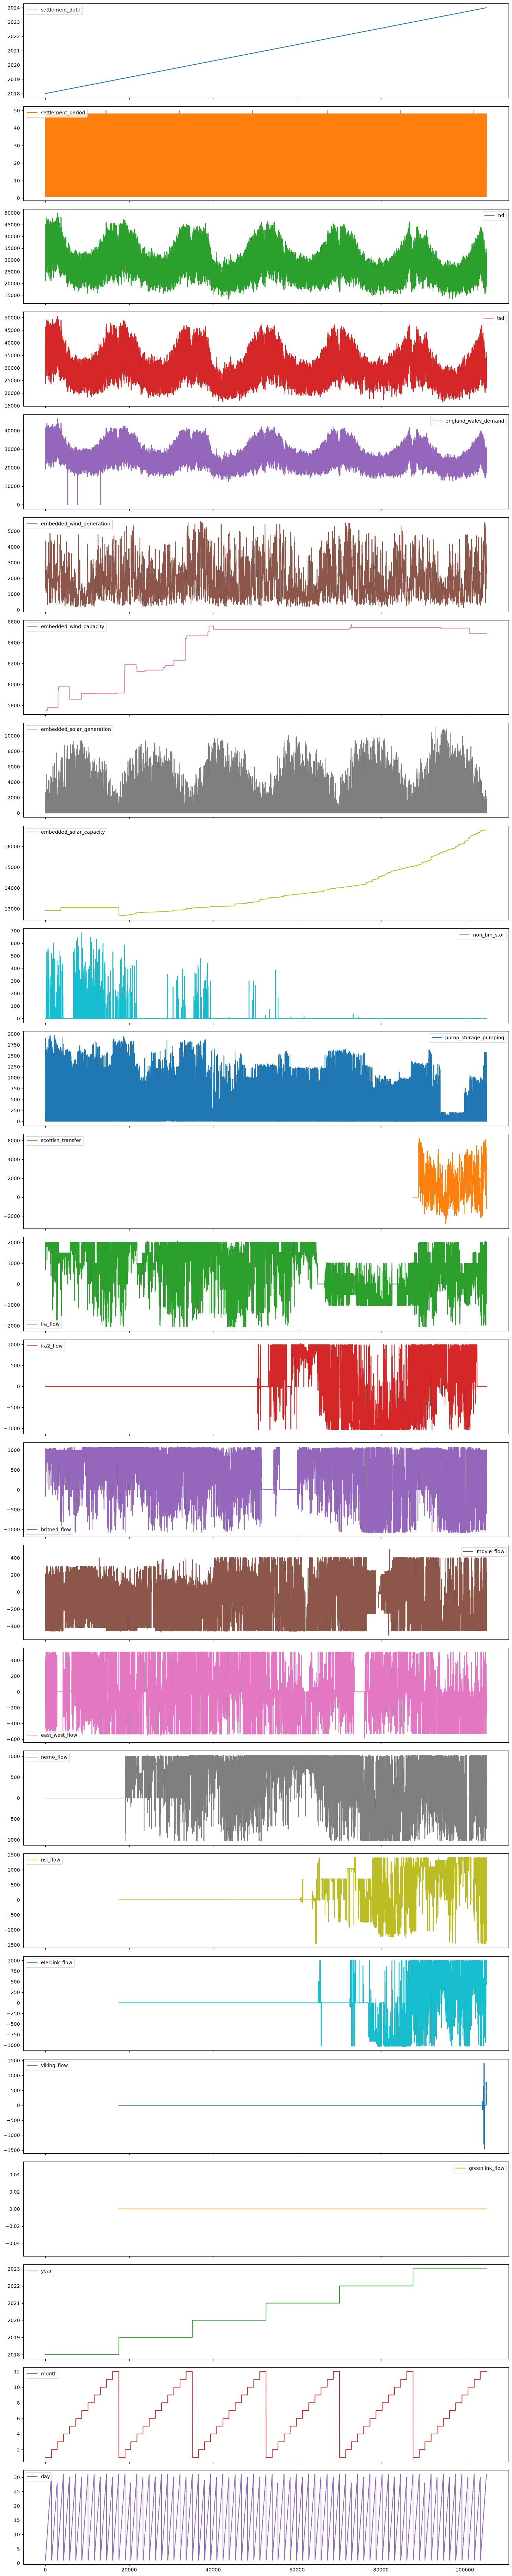

In [25]:
# One panel per column, all sharing the same time axis
#df_merged.set_index('settlement_date', inplace=True)
num_cols = 1
num_rows = math.ceil(len(df_merged.columns) / num_cols)

df_merged.plot(
    subplots=True,
    layout=(num_rows, num_cols),
    figsize=(15, 3 * num_rows),
    sharex=True,  # Keeps timelines aligned
    sharey=False,  # Allows each column to keep its own scale
)

plt.tight_layout()
plt.show()

**Notes: each column over time**
- **Capacity vs generation:** capacity is the most the panels or turbines *could* produce. Generation is what they *actually* produced in that half-hour.
- **ND:** high in winter, low in summer, every year. Slowly drifts down over the six years.
    - The model must allow for this yearly cycle, or every winter will look like an anomaly.
- **england_wales_demand:** drops to 0 three times in 2018, while ND stays normal. These are recording errors, not real events. Errors and anomalies must be kept apart.
- **Embedded solar:** the opposite cycle to ND: high in summer, low in winter.
- **Capacity columns:** NESO estimates that change slowly and get revised (they drop in 2019). Not useful here.

In [26]:
# List the columns
df_merged.columns

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day'],
      dtype='str')

In [55]:
# Drop the two capacity columns (estimates that barely change from one half-hour to the next), then save
df_merged.drop(columns = ['embedded_wind_capacity','embedded_solar_capacity'], inplace = True)
df_merged.to_parquet("../data/df_merged.parquet", engine="pyarrow", index=False)

### Build a timestamp
Each half-hour is split across two columns: the date, and the period (1–48). This joins them into one date-and-time.

Time = date + (period − 1) × 30 minutes. For example: period 1 = 00:00, period 2 = 00:30, period 3 = 01:00.

In [28]:
# Make sure the date is a real date
df_merged.settlement_date= pd.to_datetime(df_merged.settlement_date)
# Minutes after midnight for each period: period 1 = 0, period 2 = 30, period 3 = 60 ...
time_period = (df_merged.settlement_period - 1)*30

# Add those minutes to the date to get the timestamp
df_merged['timestamp'] = df_merged.settlement_date + pd.to_timedelta(time_period, unit = 'm')

In [29]:
# Use the timestamp as the row label (index)
# (This is replaced by the GMT timestamp further down)
df_merged = df_merged.set_index('timestamp')

### Count half-hours per date
Every date should have 48 rows. Any other count needs explaining.

In [30]:
# Look at the day column
df_merged.day

timestamp
2018-01-01 00:00:00     1
2018-01-01 00:30:00     1
2018-01-01 01:00:00     1
2018-01-01 01:30:00     1
2018-01-01 02:00:00     1
                       ..
2023-12-31 21:30:00    31
2023-12-31 22:00:00    31
2023-12-31 22:30:00    31
2023-12-31 23:00:00    31
2023-12-31 23:30:00    31
Name: day, Length: 105168, dtype: int32

In [31]:
# Count the rows for each date
results = df_merged.settlement_date.value_counts()
# Keep only the dates that don't have 48
abnormal_rows = results[results != 48]
# Result: 12 dates (two per year)
abnormal_rows

settlement_date
2018-10-28    50
2019-10-27    50
2020-10-25    50
2021-10-31    50
2022-10-30    50
2023-10-29    50
2018-03-25    46
2019-03-31    46
2020-03-29    46
2021-03-28    46
2022-03-27    46
2023-03-26    46
Name: count, dtype: int64

**Result: 12 dates don't have 48 half-hours. All of them are clock-change days.**
- **46:** the last Sunday in March. The clocks go forward, so the day is an hour shorter.
- **50:** the last Sunday in October. The clocks go back, so the day is an hour longer.
- Every other date has exactly 48, so **no half-hours are missing**.

**Problem:** the periods follow UK clock time, so the timestamp formula breaks on these 12 days. October's extra periods clash with the next day, and March gets times that never existed.

**Fix:** build the timestamp in GMT, which has no clock changes. The data has no gaps, so start at 2018-01-01 00:00 GMT and add 30 minutes for every row.

In [89]:
# 1. Sort the rows into time order
df_merged = df_merged.sort_values(by=['settlement_date', 'settlement_period']).reset_index(drop=True)
# 2. One timestamp per row: start at 2018-01-01 00:00 GMT, then add 30 minutes for each row
gmt_timestamps = pd.date_range(
    start='2018-01-01 00:00:00',
    periods=len(df_merged),
    freq='30min',
    tz='Etc/GMT'
)
df_merged['timestamp'] = gmt_timestamps

In [33]:
# Re-check: still 12 dates, as expected.
# This counts the ORIGINAL settlement_date column, which still holds the clock-change days.
# The new GMT timestamp itself runs continuously in 30-minute steps.
result = df_merged.settlement_date.value_counts()
result[result != 48]

settlement_date
2018-10-28    50
2019-10-27    50
2020-10-25    50
2021-10-31    50
2022-10-30    50
2023-10-29    50
2018-03-25    46
2019-03-31    46
2020-03-29    46
2021-03-28    46
2022-03-27    46
2023-03-26    46
Name: count, dtype: int64

### Duplicates
Check for two rows with the same date and period.

In [34]:
df_merged[df_merged.duplicated(subset=["settlement_date", "settlement_period"])] # Result: no duplicates

,settlement_date,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_wind_capacity,embedded_solar_generation,embedded_solar_capacity,non_bm_stor,...,east_west_flow,nemo_flow,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day,timestamp


### Missing values
Count the blank (NaN) cells in each column.

In [35]:
df_merged.isna().sum()
# Blank cells only appear in columns that didn't exist in some years' files:
# scottish_transfer: 87,648 blank (it only exists in 2023)
# nsl_flow, eleclink_flow, viking_flow, greenlink_flow: 17,520 blank each (missing in 2018)

settlement_date                  0
settlement_period                0
nd                               0
tsd                              0
england_wales_demand             0
embedded_wind_generation         0
embedded_wind_capacity           0
embedded_solar_generation        0
embedded_solar_capacity          0
non_bm_stor                      0
pump_storage_pumping             0
scottish_transfer            87648
ifa_flow                         0
ifa2_flow                        0
britned_flow                     0
moyle_flow                       0
east_west_flow                   0
nemo_flow                        0
nsl_flow                     17520
eleclink_flow                17520
viking_flow                  17520
greenlink_flow               17520
year                             0
month                            0
day                              0
timestamp                        0
dtype: int64

In [36]:
# Rows where england_wales_demand is 0
df_merged[df_merged.england_wales_demand == 0]
# 3 single half-hours in 2018. ND and TSD look normal on all three, so only this column failed to record.
# They're zeros, not NaN, so the missing-value check above doesn't catch them: "missing values recorded as 0".
# TSD = ND + 500 on all three. This matches NESO's note that TSD includes 500 MW of power-station use in summer time.
# These rows also confirm the GMT timestamp: e.g. 22 April, period 16 = 07:30 UK summer time = 06:30 GMT.

,settlement_date,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_wind_capacity,embedded_solar_generation,embedded_solar_capacity,non_bm_stor,...,east_west_flow,nemo_flow,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day,timestamp
5341,2018-04-22,16,21830,22330,0,1436,5978,1580,13052,0,...,0,0,NaN,NaN,NaN,NaN,2018,4,22,2018-04-22 06:30:00+00:00
7664,2018-06-09,35,26870,27370,0,402,5859,3420,13052,0,...,0,0,NaN,NaN,NaN,NaN,2018,6,9,2018-06-09 16:00:00+00:00
13191,2018-10-02,42,34190,34690,0,2263,5911,2,13052,0,...,0,0,NaN,NaN,NaN,NaN,2018,10,2,2018-10-02 19:30:00+00:00


### Summary statistics
Median, quartiles and high percentiles for every numeric column. Used to check skew and spot impossible values.

In [37]:
# Summary stats, including the 99th and 99.99th percentiles
df_merged.describe(include = 'number', percentiles = [0.5, 0.75,0.99, 0.9999])

,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_wind_capacity,embedded_solar_generation,embedded_solar_capacity,non_bm_stor,pump_storage_pumping,...,moyle_flow,east_west_flow,nemo_flow,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day
count,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,...,105168.000000,105168.000000,105168.000000,87648.000000,87648.000000,87648.000000,87648.0,105168.000000,105168.00000,105168.000000
mean,24.500228,27963.008976,29594.285705,25561.344316,1813.965227,6363.900721,1397.683773,13859.162882,4.463211,221.554560,...,-87.559182,0.536370,391.735461,290.496885,17.008021,1.132336,0.0,2020.499772,6.52476,15.726685
std,13.853860,6550.868025,6237.335170,5983.504108,1133.530640,253.976368,2166.812211,1092.404192,36.024023,420.648911,...,273.441400,304.732528,557.306818,581.593902,429.693435,40.942019,0.0,1.707477,3.44843,8.798960
min,1.000000,13367.000000,16513.000000,0.000000,147.000000,5754.000000,0.000000,12663.000000,0.000000,0.000000,...,-505.000000,-585.000000,-1022.000000,-1455.000000,-1028.000000,-1465.000000,0.0,2018.000000,1.00000,1.000000
50%,24.500000,27202.000000,28823.000000,24814.000000,1532.000000,6527.000000,6.000000,13463.000000,0.000000,11.000000,...,-62.000000,0.000000,565.000000,0.000000,0.000000,0.000000,0.0,2020.000000,7.00000,16.000000
75%,36.250000,32167.000000,33428.000000,29414.000000,2501.000000,6538.000000,2263.000000,14425.000000,0.000000,140.250000,...,132.000000,185.000000,902.000000,693.000000,0.000000,0.000000,0.0,2022.000000,10.00000,23.000000
99%,48.000000,43840.330000,45146.000000,40019.330000,4940.330000,6559.000000,8353.660000,16762.000000,181.000000,1584.000000,...,401.000000,504.000000,1019.000000,1399.000000,999.000000,0.000000,0.0,2023.000000,12.00000,31.000000
99.99%,49.000000,47879.349700,49093.666000,43980.383100,5571.000000,6574.000000,10718.216100,16792.000000,607.933200,1916.483300,...,491.483300,504.000000,1020.000000,1400.000000,1001.000000,1408.000000,0.0,2023.000000,12.00000,31.000000
max,50.000000,49807.000000,50608.000000,46356.000000,5605.000000,6574.000000,11116.000000,16793.000000,684.000000,1963.000000,...,499.000000,504.000000,1033.000000,1401.000000,1002.000000,1408.000000,0.0,2023.000000,12.00000,31.000000


**Notes: summary stats**
- 105,168 rows = 6 × 17,520 + 48 (the 2020 leap day). The timeline is complete.
- **ND:** median 27,202 MW, mean 27,963 MW. The mean is above the median, so ND is right-skewed. Max 49,807 MW is high but realistic: no impossible values.
- **Embedded solar:** median 6 MW, because about half of all half-hours are at night.
- **england_wales_demand:** min 0 (the three error rows above).
- **Counts:** scottish_transfer has 17,520 values (one year, 2023). nsl, eleclink, viking and greenlink have 87,648 (2019–2023).

### Histogram of ND
Does ND have one peak or several?

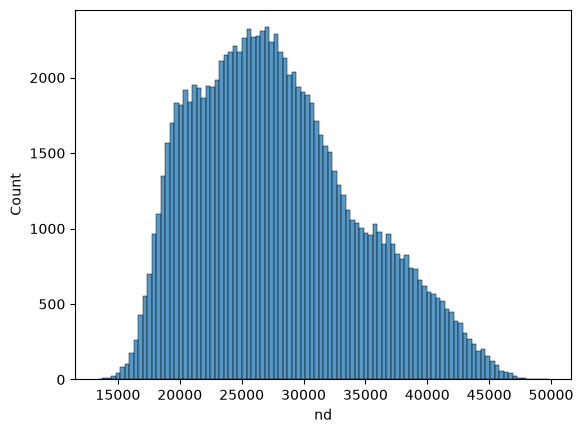

In [40]:
# Histogram of all ND values, 100 bins
t = sns.histplot(df_merged, x = 'nd', bins = 100)
#t.xticks(rotation=90)
#t.plt.show()

### ND histograms by month (2018 only, first week of each month)
Does the shape change through the year?

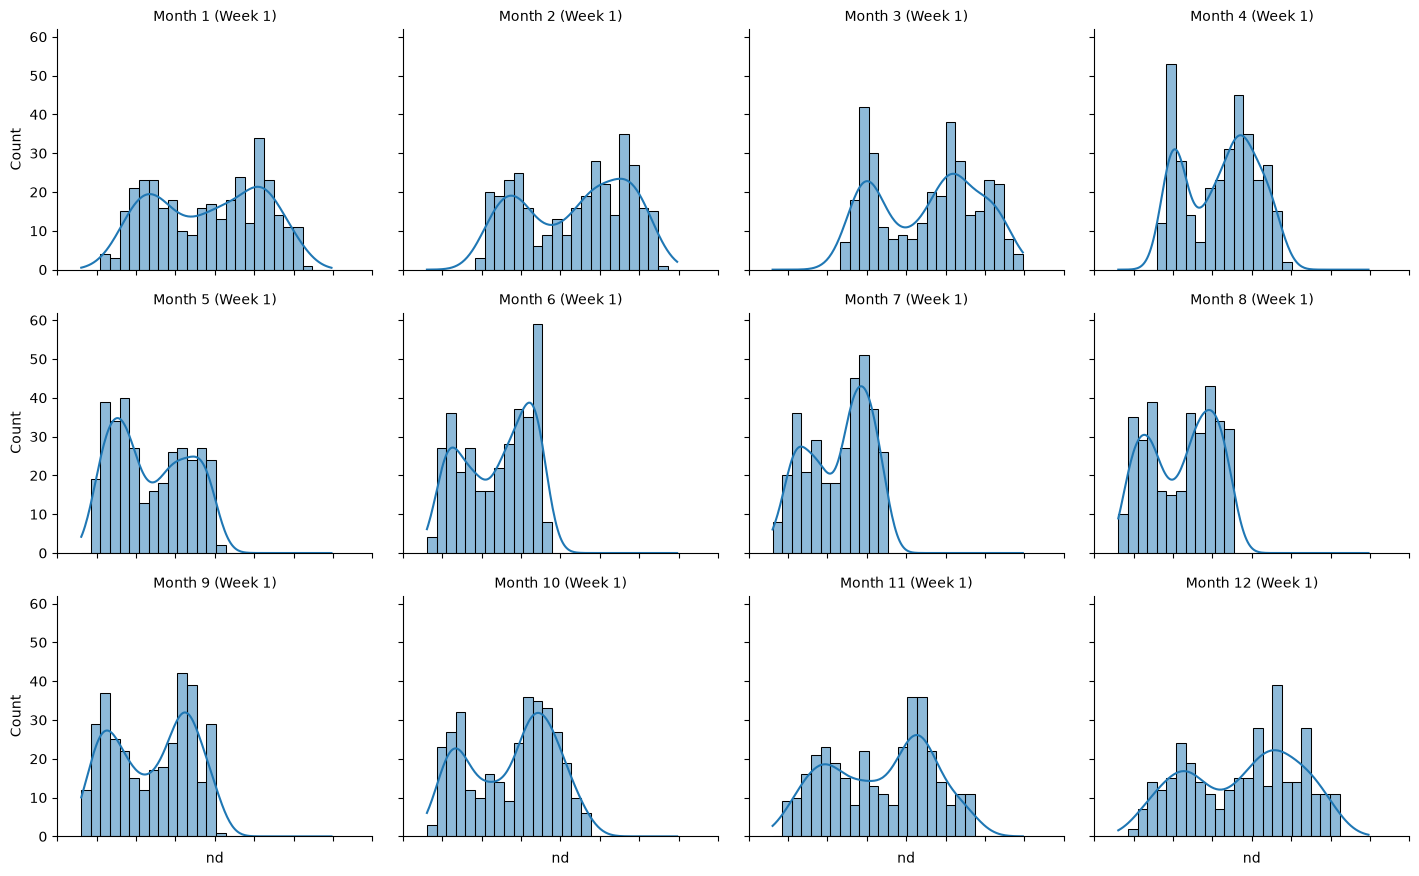

In [41]:
# 2018 only
y_18 = df_merged[df_merged["year"] == 2018]

# Days 1-7 of each month
all_months_week_1 = y_18[y_18["day"].isin(range(1, 8))]

# One histogram per month
g = sns.displot(
    data=all_months_week_1,
    x="nd",
    col="month",
    col_wrap=4,
    kind="hist",
    height=3,
    aspect=1.2,
    kde = True
)

# Titles and labels
g.set_titles("Month {col_name} (Week 1)")
g.set_axis_labels("nd", "Count")
g.set_xticklabels(rotation=90)
plt.show()

**Notes: ND histograms**

Overall histogram
- ND ranges from about 13,000 to 50,000 MW.
- Right-skewed: most values are 18,000–32,000, with a long tail up to 50,000.
- Lumpy shape with several bumps: several distributions are mixed together.

Monthly histograms (2018, first week of each month)
- Most months have **two peaks**: a low one (night) and a high one (day).
- Winter (Nov–Feb): higher and wider, about 20,000–48,000.
- Summer (May–Aug): lower and narrower, about 18,000–33,000.
- The lumpy overall histogram is these monthly day/night shapes stacked together.

What this means
- "Normal" demand depends on time of day and season. 30,000 MW is normal on a winter night but high on a summer night.
- So anomalies must be judged against the same time of day and season, not against the overall average.
- **Skew: no transform needed.** It comes from mixing seasons and times of day, not from outliers. The detector removes these patterns later (STL), and Isolation Forest doesn't need normally distributed data.
- Use the median rather than the mean to describe ND, because of the skew.

**Summary:** ND has two peaks within each month, a low night-time one and a high daytime one. Both move up and spread out in winter.

## 3. Bivariate analysis (how other columns relate to ND)

**Aim of the model:** flag half-hours when ND is unusually high or low compared with what's normal for that time of day, day of week and season.

This is **unsupervised**: there's no label column saying "anomaly". ND is the series being monitored.

**So the question here is:** what explains *normal* ND? Whatever these factors explain counts as "expected". Only what's left over can be an anomaly.

| Compare ND with | Plot | Question |
| --- | --- | --- |
| Time of day | Boxplot per half-hour | How strong is the daily pattern? |
| Day of week | Boxplot per weekday | How different are weekends? |
| Month | Boxplot per month | How strong is the yearly cycle? |
| Year | Boxplot per year | How big is the downward trend? |
| Embedded solar | Scatter, summer midday | Does solar lower ND? |
| Embedded wind | Scatter | Does wind lower ND? |
| TSD, England & Wales | Correlation | Are they just copies of ND? |

### Time of day
One box per half-hour, in **UK clock time**. People follow the clock on the wall, so the morning rise happens at the same clock time all year.

In [ ]:
df_merged.columns
# Copy the table for this plot
hour_df = df_merged.copy()
# Convert the GMT timestamp to UK clock time
hour_df['timestamp_raw'] = pd.to_datetime(hour_df['timestamp']).dt.tz_convert('Europe/London')

C:\Users\jagmeet\AppData\Local\Temp\ipykernel_16148\819758627.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="timestamp_raw", y="nd", data=hour_df, palette="pastel")


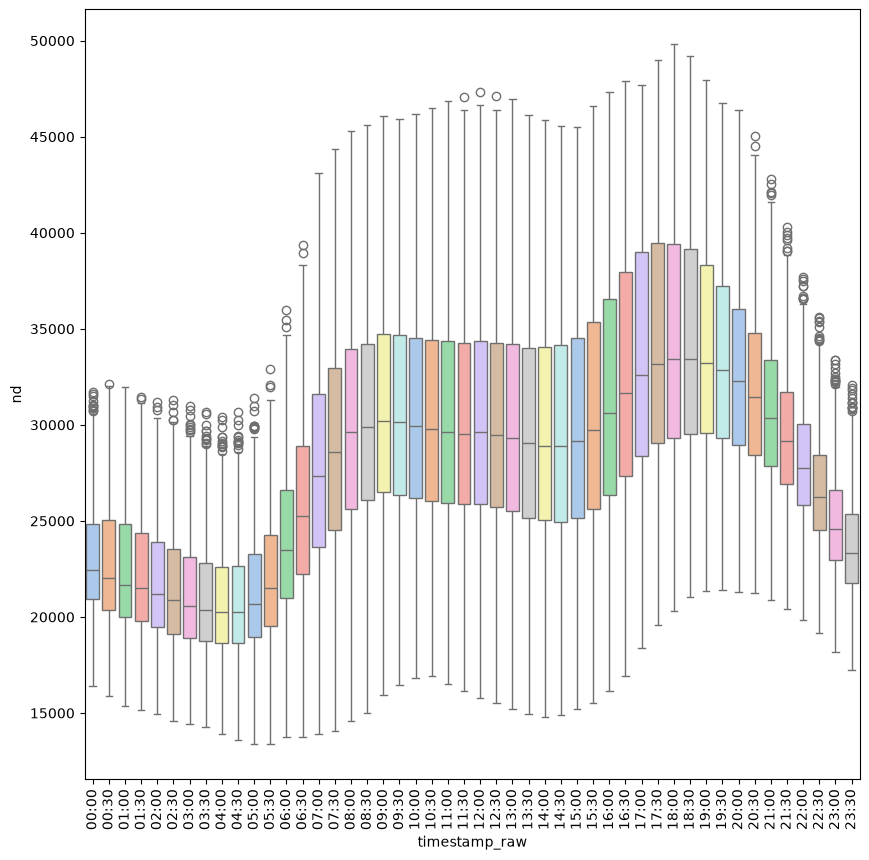

In [43]:
# Keep just the clock time as text, e.g. '08:30'
hour_df['timestamp_raw'] = hour_df['timestamp_raw'].dt.strftime('%H:%M')

# One box per half-hour of the day
plt.figure(figsize=(10, 10))
sns.boxplot(x="timestamp_raw", y="nd", data=hour_df, palette="pastel")
plt.xticks(rotation=90)
plt.show()

**Notes: time of day**
- Lowest at about **04:00** (median about 20,200 MW).
- Rises steeply from 05:30 to 09:00.
- Flat through the day at about 29,000–30,000 MW, with a small dip in the early afternoon (likely solar).
- Highest at **17:30–18:30** (median about 33,400 MW): the evening peak.
- Falls back to about 23,000 MW by 23:30.
- **Effect size:** about 13,000 MW between the lowest and highest medians. The biggest pattern in the data.
- The evening boxes are the tallest: evenings change most with season (dark, cold winter evenings vs light summer ones).

### Day of week
One box per weekday (Monday–Sunday), in UK clock time.

**Fixed:** the first version used the `day` column, which is the day of the *month* (1–31), not the weekday.

In [ ]:
# Make a weekday column (Monday-Sunday) from the timestamp, in UK clock time
df_merged['weekday'] = df_merged['timestamp'].dt.tz_convert('Europe/London').dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# One box per weekday, in calendar order
plt.figure(figsize=(10, 10))
sns.boxplot(x='weekday', y='nd', data=df_merged, order=weekday_order, palette='pastel')
plt.xticks(rotation=90)
plt.show()

**Notes: day of week** *(fill in after running)*
- Weekday medians:
- Saturday and Sunday medians:
- Effect size (gap between the highest and lowest medians, MW):

### Month
One box per month (1 = January). How strong is the yearly cycle?

C:\Users\jagmeet\AppData\Local\Temp\ipykernel_16148\1192174917.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'month', y= 'nd', data = df_merged, palette = 'pastel')


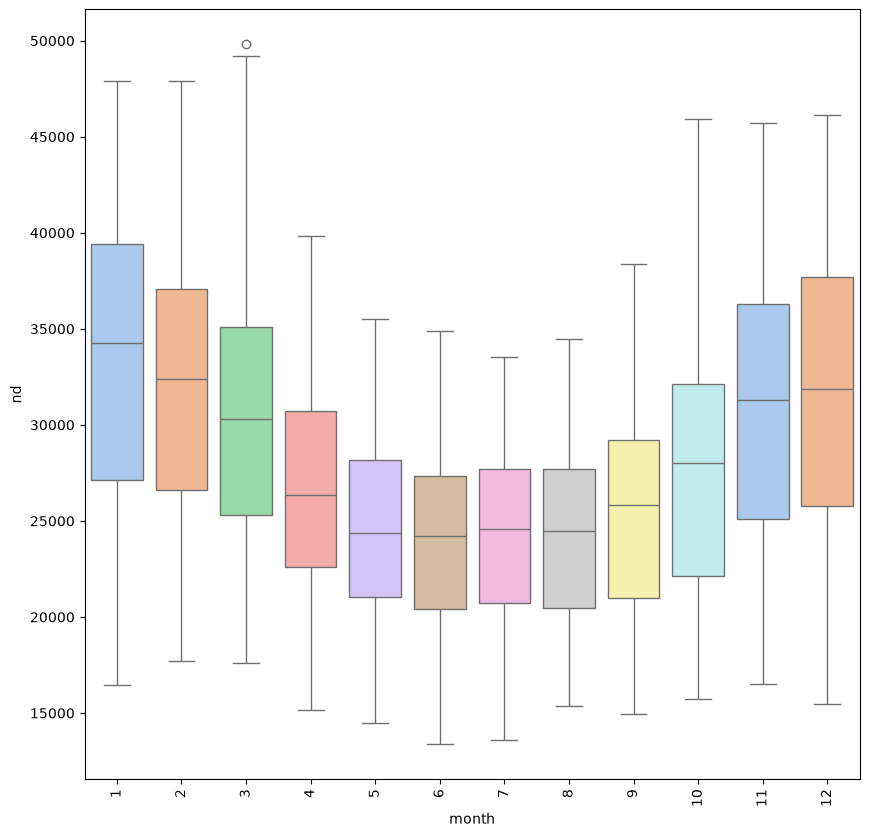

In [45]:
# One box per month
plt.figure(figsize = (10,10))
sns.boxplot(x = 'month', y= 'nd', data = df_merged, palette = 'pastel')
plt.xticks(rotation = 90)
plt.show()

**Notes: month**
- Highest in **January** (median about 34,300 MW), lowest in **June** (about 24,200 MW).
- A smooth U-shape: falls from January to June, then rises again from September.
- **Effect size:** about 10,000 MW between the highest and lowest medians.
- Winter boxes are taller: winter demand varies more (cold snaps, dark evenings).

### Year
One box per year. How big is the downward trend?

C:\Users\jagmeet\AppData\Local\Temp\ipykernel_16148\3934392146.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'year', y = 'nd', data = df_merged, palette = 'pastel')


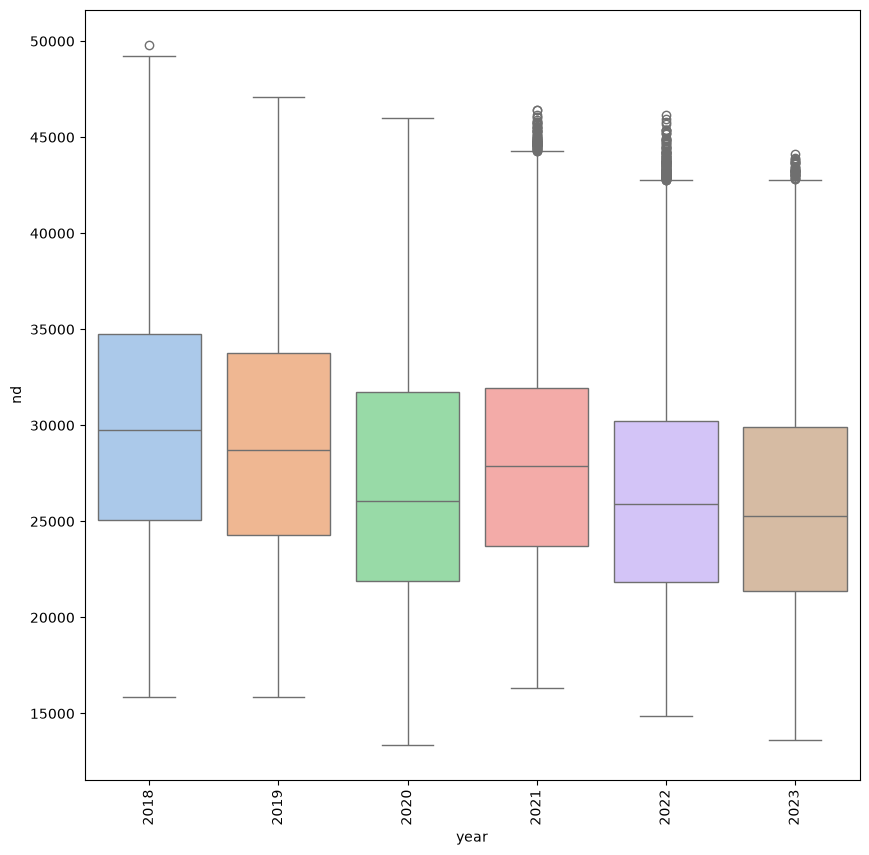

In [46]:
# One box per year
plt.figure(figsize = (10,10))
sns.boxplot(x = 'year', y = 'nd', data = df_merged, palette = 'pastel')
plt.xticks(rotation = 90)
plt.show()

**Notes: year**
- The median falls from about **29,700 MW (2018)** to **25,300 MW (2023)**: about 4,400 MW, or 15%, over six years.
- **2020 dips** (about 26,000), then **2021 recovers** (about 27,900). This fits the Covid lockdowns: a known event to check later.
- 2022 and 2023 fall further. Possible causes: more rooftop solar, and the 2022 energy price rise (not tested here).
- The dots above the boxes in 2021–2023 are high winter peaks, not errors. As the boxes move down, the same cold-winter peaks now count as outliers.
- **Effect size:** smaller than time of day or month, but steady, so the detector must include a trend.

### Solar
About half of all half-hours are at night, when solar is 0. To see solar's effect, keep only **midday in summer** (May–August).

Note: the filter uses the GMT hour. 12:00 GMT = 13:00 UK summer time.

In [ ]:
# Keep only summer months (May-August) at 12:00-12:30 GMT (13:00-13:30 UK summer time)
summer_df = hour_df[
    (hour_df['timestamp'].dt.month.isin([5,6,7,8]))&
    (hour_df['timestamp'].dt.hour.isin([12]))
]
summer_df

,settlement_date,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_wind_capacity,embedded_solar_generation,embedded_solar_capacity,non_bm_stor,...,nemo_flow,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day,timestamp,timestamp_raw
5784,2018-05-01,27,29006,30391,27016,3013,5978,6570,13052,0,...,0,NaN,NaN,NaN,NaN,2018,5,1,2018-05-01 12:00:00+00:00,13:00
5785,2018-05-01,28,28878,30326,26891,3105,5978,6230,13052,0,...,0,NaN,NaN,NaN,NaN,2018,5,1,2018-05-01 12:30:00+00:00,13:30
5832,2018-05-02,27,32132,33104,29352,2948,5859,5420,13052,0,...,0,NaN,NaN,NaN,NaN,2018,5,2,2018-05-02 12:00:00+00:00,13:00
5833,2018-05-02,28,31376,32317,28657,2909,5859,5880,13052,0,...,0,NaN,NaN,NaN,NaN,2018,5,2,2018-05-02 12:30:00+00:00,13:30
5880,2018-05-03,27,29961,30944,27184,1740,5859,6560,13052,0,...,0,NaN,NaN,NaN,NaN,2018,5,3,2018-05-03 12:00:00+00:00,13:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99193,2023-08-29,28,25784,27723,24058,1765,6538,4490,16111,0,...,-445,1399.0,48.0,0.0,0.0,2023,8,29,2023-08-29 12:30:00+00:00,13:30
99240,2023-08-30,27,24095,25578,21665,1411,6538,6697,16114,0,...,412,1399.0,261.0,0.0,0.0,2023,8,30,2023-08-30 12:00:00+00:00,13:00
99241,2023-08-30,28,23819,25302,21338,1396,6538,6461,16114,0,...,414,1399.0,276.0,0.0,0.0,2023,8,30,2023-08-30 12:30:00+00:00,13:30
99288,2023-08-31,27,26634,28118,24038,752,6538,5336,16118,0,...,994,1399.0,999.0,0.0,0.0,2023,8,31,2023-08-31 12:00:00+00:00,13:00


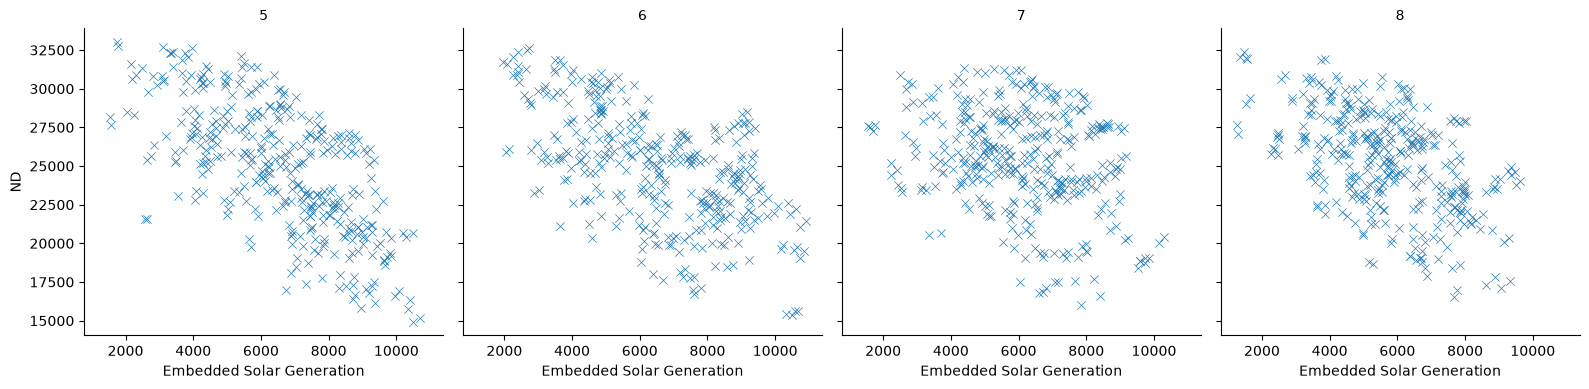

In [49]:
# Scatter of ND against solar, one panel per month
g = sns.FacetGrid(summer_df, col="month", col_wrap=4, height=4, sharex=True, sharey=True)

g.map_dataframe(sns.scatterplot, x="embedded_solar_generation", y="nd", marker="x")

g.set_titles(col_template="{col_name}")
g.set_axis_labels("Embedded Solar Generation", "ND")

plt.show()

**Notes: solar (summer midday)**
- May, June and August: a clear downward slope. ND falls from about 30,000–32,000 at low solar to 15,000–20,000 at high solar.
- July: flatter and more scattered, but still slightly downward.
- Real but noisy: at any solar level, ND still varies by 8,000–10,000 MW.
- ND drops by more than the extra solar supplies, so something else adds to the drop. Likely the downward trend across years, and weekends.

### Wind
Wind against ND across all hours and months, one panel per year.

In [51]:
# List the columns
df_merged.columns

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day'],
      dtype='str')

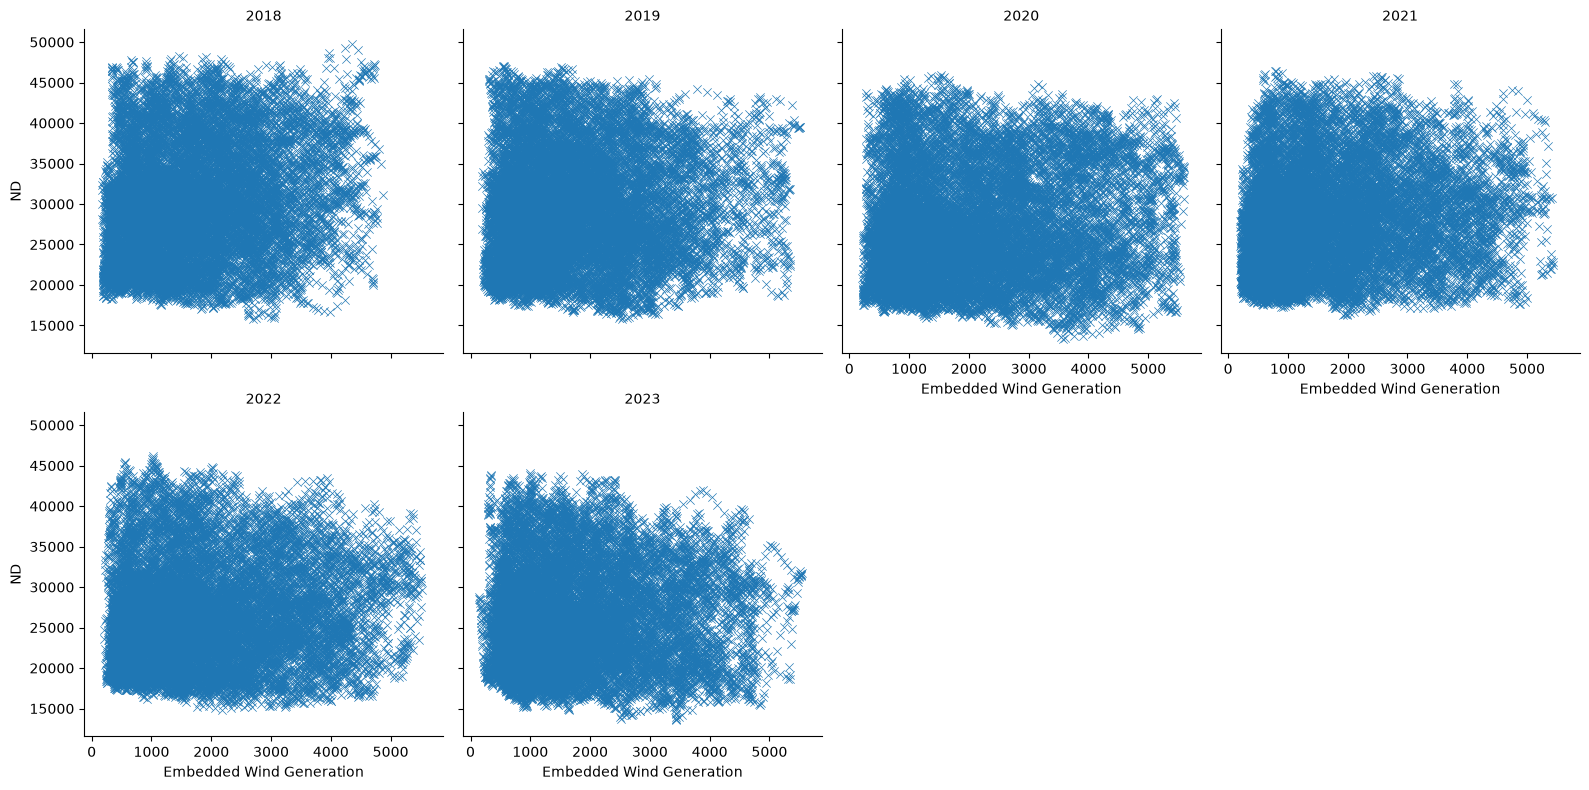

In [53]:
# Scatter of ND against wind, one panel per year
g = sns.FacetGrid(df_merged, col="year", col_wrap=4, height=4, sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, x="embedded_wind_generation", y="nd", marker="x")

g.set_titles(col_template="{col_name}")
g.set_axis_labels("Embedded Wind Generation", "ND")

plt.show()

**Notes: wind (all data)**
- No clear pattern: a shapeless cloud in every year.
- This doesn't prove wind has no effect. Season may be hiding it (tested below).

### Correlation between the main columns
Correlation (r) runs from −1 to +1. It measures how closely two columns move together in a straight line.

Uses a random sample of 5,000 rows to keep it fast.

In [63]:
# Random sample of 5,000 rows
df = df_merged.sample(5000, random_state=42, ignore_index = True)

In [71]:
# Keep the demand and generation columns
df = df[['nd', 'tsd', 'england_wales_demand', 'embedded_wind_generation', 'embedded_solar_generation', 'pump_storage_pumping']]

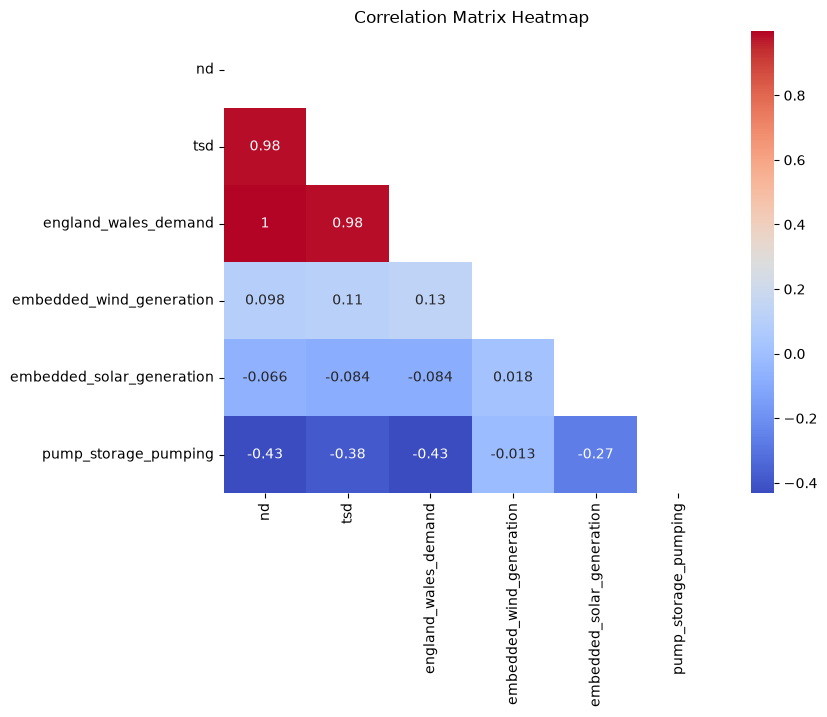

In [77]:
# Correlation between every pair of columns
corr_matrix = df.corr(numeric_only = True)
# Hide the top half (it repeats the bottom half)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=0)

# Heatmap with the numbers shown
plt.figure(figsize = (8,6))

sns.heatmap(corr_matrix, mask = mask, annot = True, cmap ='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()

**Notes: correlation (all data)**
- **ND, TSD and England & Wales** are near-copies (0.98–1.00). England & Wales is part of ND, and TSD is ND plus a few extras.
- **Solar and wind** are close to 0. This is misleading (tested below).
- **Pump storage (−0.43):** pumping happens at night, when demand is low. It's about timing, not a cause.
- **Lesson:** correlation only finds straight-line patterns across the whole dataset. Here the important patterns depend on time of day and season.

### Solar correlation: summer midday only
Over all the data, solar's effect is hidden because:
- solar is 0 for about half of all half-hours (night), and
- summer has both more solar and lower demand.

So this uses the summer-midday rows from above, where time of day and season are held roughly fixed.

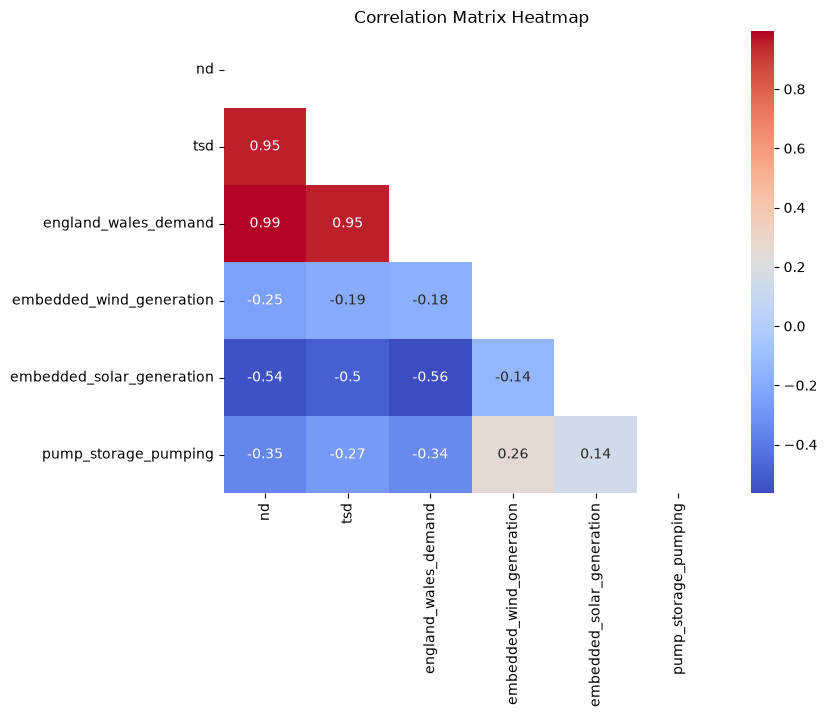

In [ ]:
# Same correlation heatmap, summer midday rows only
summer_df_cols = summer_df[['nd', 'tsd', 'england_wales_demand', 'embedded_wind_generation', 'embedded_solar_generation', 'pump_storage_pumping']]
corr_matrix_summer = summer_df_cols.corr(numeric_only = True)
mask_summer = np.triu(np.ones_like(corr_matrix_summer, dtype=bool), k=0)

plt.figure(figsize = (8,6))

sns.heatmap(corr_matrix_summer, mask = mask_summer, annot = True, cmap ='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()

### Wind correlation: winter 18:00 only
Wind isn't 0 at night (its minimum is 147 MW), so night isn't the problem for wind.

The problem is season: winter is windier **and** has higher demand, which can hide wind's effect.

So this keeps one season and one time (October–February, 18:00 GMT) to compare like with like.

Note: October is partly UK summer time, so for part of that month 18:00 GMT = 19:00 UK time.

In [91]:
# List the columns
df_merged.columns

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_solar_generation', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day', 'timestamp', 'timestamp_raw'],
      dtype='str')

In [90]:
# Add UK clock time as text (same as for the time-of-day plot)
df_merged['timestamp_raw'] = pd.to_datetime(df_merged['timestamp']).dt.tz_convert('Europe/London')
df_merged['timestamp_raw'] = df_merged['timestamp_raw'].dt.strftime('%H:%M')

# Keep October-February at 18:00-18:30 GMT
wind_df = df_merged[
    (df_merged['timestamp'].dt.month.isin([10,11,12,1,2]))&
    (df_merged['timestamp'].dt.hour.isin([18]))
]

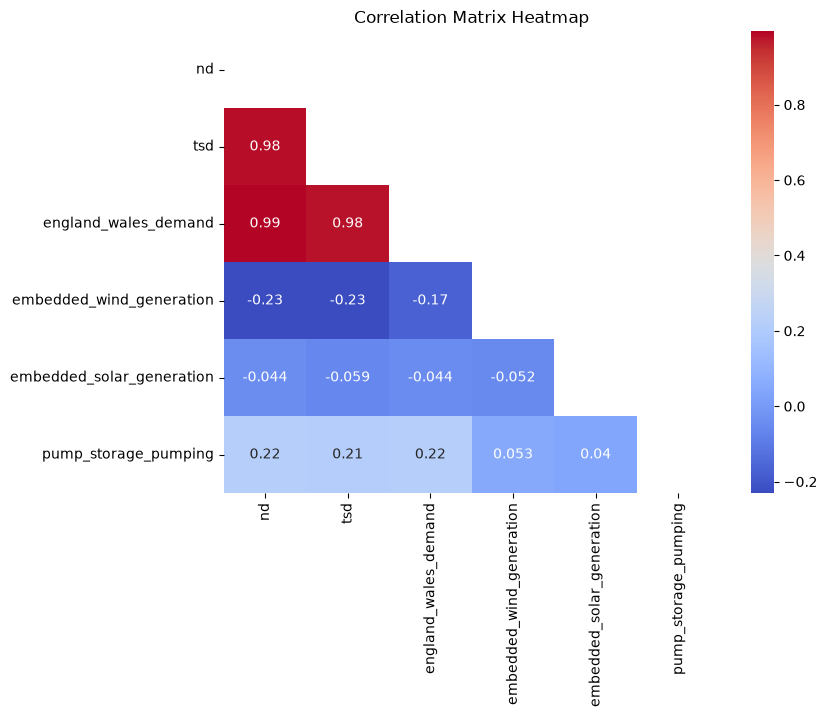

In [94]:
# Same correlation heatmap, winter 18:00 rows only
wind_df = wind_df[['nd', 'tsd', 'england_wales_demand', 'embedded_wind_generation', 'embedded_solar_generation', 'pump_storage_pumping']]
corr_matrix_wind = wind_df.corr(numeric_only = True)
mask_wind = np.triu(np.ones_like(corr_matrix_wind, dtype=bool), k=0)

plt.figure(figsize = (8,6))

sns.heatmap(corr_matrix_wind, mask = mask_wind, annot = True, cmap ='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()

**Notes: solar and wind, with season and time held fixed**

| | All data | Season and time held fixed |
| --- | --- | --- |
| Solar vs ND | −0.07 | **−0.54** (summer midday) |
| Wind vs ND | +0.10 | **−0.23** (winter 18:00) |

**Solar**
- A real negative effect, hidden in the full data by night-time zeros and season.
- **Confounder (summer):** summer brings more solar *and* lower demand (less heating and lighting). This makes the raw link look stronger than it is.
- **Solar's own effect:** even with summer held fixed, more solar = lower ND. Rooftop panels supply homes directly, so less is drawn from the grid. Solar lowers **grid demand (ND)**, not how much electricity people use.

**Wind**
- The sign **flips**: +0.10 overall, −0.23 with season and time held fixed.
- **Confounder (winter):** winter is windier *and* has higher demand. So across all the data, wind and ND rise together, even though wind itself lowers ND.
- Wind's effect is weaker than solar's (there's less embedded wind than solar).

**Caveat:** this is consistent with seasonal confounding, not proof of it. Temperature moves with season too.

**For the model:** solar and wind both explain part of normal ND, so they're useful extra inputs.

## 4. Time-series checks

### Autocorrelation (ACF)
Autocorrelation measures how similar ND is to itself shifted back in time.

Peaks at a lag of **48** (one day) and **336** (one week) would confirm the daily and weekly cycles to use in STL later.

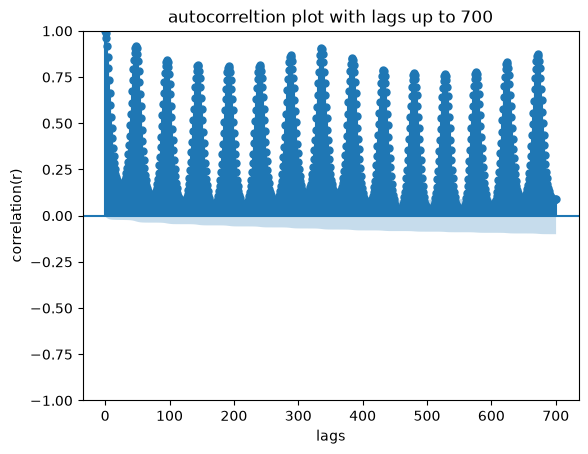

In [97]:
plot_acf(df_merged.nd, lags = 700)
plt.xlabel('lags')
plt.ylabel('correlation(r)')
plt.title('autocorreltion plot with lags up to 700')
plt.show()

**Notes: autocorrelation**:
- y-axis (r): how similar ND is to itself that many steps back. 1 = identical, 0 = no link.
- At each peak (whole days back), r is about 0.8–0.9: same time on a different day, so very similar.
- Between peaks (half a day back), r drops to about 0.05–0.1: daytime compared with night-time, so very different.
- 14 bumps = 14 days. The daily cycle repeats reliably.


NOTES FOR ACF AND MSTL; HOW THEY WORK TOGETHER:
- ND is made of a trend, a daily pattern, a weekly pattern and a seasonal swing, plus a leftover. 
- ACF measures how often the patterns repeat: every 48 half-hours (daily) and every 336 (weekly). 
- MSTL uses those two numbers to separate the patterns from the data. 
- What’s left is the leftover (residual): normally small noise. 
- When the residual is much bigger than usual, demand was unusually high or low for that time, and it gets flagged as an anomaly, usually as a run of neighbouring half-hours rather than a single one.

### One normal week
Zoom into one ordinary week (for example, the second week of March 2019) to see the daily shape and the weekday/weekend difference.

In [103]:
df_merged.dtypes

settlement_date                       datetime64[us]
settlement_period                              int64
nd                                             int64
tsd                                            int64
england_wales_demand                           int64
embedded_wind_generation                       int64
embedded_solar_generation                      int64
non_bm_stor                                    int64
pump_storage_pumping                           int64
scottish_transfer                            float64
ifa_flow                                       int64
ifa2_flow                                      int64
britned_flow                                   int64
moyle_flow                                     int64
east_west_flow                                 int64
nemo_flow                                      int64
nsl_flow                                     float64
eleclink_flow                                float64
viking_flow                                  f

In [130]:
one_week = df_merged[
    (df_merged['timestamp'].dt.month.isin([3]))&
    (df_merged['timestamp'].dt.year.isin([2019]))&
    (df_merged['timestamp'].dt.day.isin([11,12,13,14,15,16,17]))
]
one_week # corerct 336 rows 

,settlement_date,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_solar_generation,non_bm_stor,pump_storage_pumping,scottish_transfer,...,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day,timestamp,timestamp_raw,weekday
20832,2019-03-11,1,23400,24693,21524,4255,0,0,693,NaN,...,0.0,0.0,0.0,0.0,2019,3,11,2019-03-11 00:00:00+00:00,00:00,Monday
20833,2019-03-11,2,23982,24988,22084,4241,0,0,406,NaN,...,0.0,0.0,0.0,0.0,2019,3,11,2019-03-11 00:30:00+00:00,00:30,Monday
20834,2019-03-11,3,23769,25442,21817,4348,0,0,1073,NaN,...,0.0,0.0,0.0,0.0,2019,3,11,2019-03-11 01:00:00+00:00,01:00,Monday
20835,2019-03-11,4,23262,25152,21355,4408,0,0,1290,NaN,...,0.0,0.0,0.0,0.0,2019,3,11,2019-03-11 01:30:00+00:00,01:30,Monday
20836,2019-03-11,5,22837,24720,20990,4366,0,0,1283,NaN,...,0.0,0.0,0.0,0.0,2019,3,11,2019-03-11 02:00:00+00:00,02:00,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21163,2019-03-17,44,30955,31687,28235,2186,0,0,5,NaN,...,0.0,0.0,0.0,0.0,2019,3,17,2019-03-17 21:30:00+00:00,21:30,Sunday
21164,2019-03-17,45,29293,29900,26717,2007,0,0,4,NaN,...,0.0,0.0,0.0,0.0,2019,3,17,2019-03-17 22:00:00+00:00,22:00,Sunday
21165,2019-03-17,46,27863,28473,25336,1858,0,0,10,NaN,...,0.0,0.0,0.0,0.0,2019,3,17,2019-03-17 22:30:00+00:00,22:30,Sunday
21166,2019-03-17,47,25978,26782,23608,1776,0,0,204,NaN,...,0.0,0.0,0.0,0.0,2019,3,17,2019-03-17 23:00:00+00:00,23:00,Sunday


C:\Users\jagmeet\AppData\Local\Temp\ipykernel_16148\705357497.py:5: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(x='timestamp', y='nd', data=one_week,  palette='pastel')


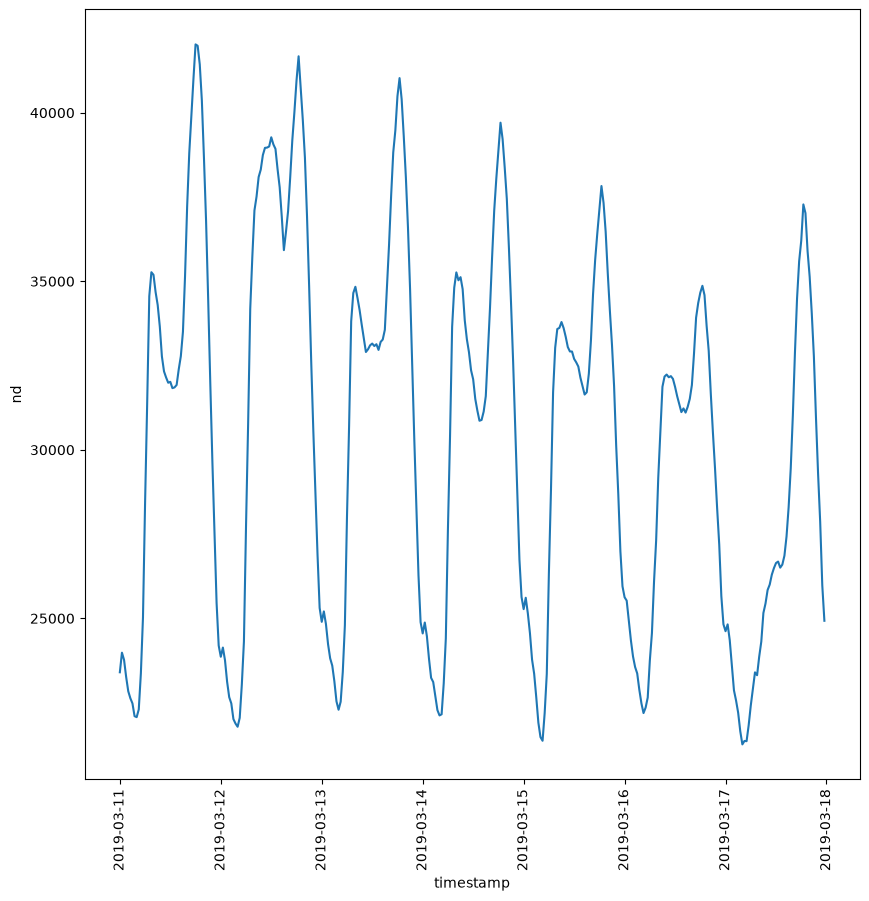

C:\Users\jagmeet\AppData\Local\Temp\ipykernel_16148\705357497.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(x='weekday', y='nd', data=one_week,  palette='pastel')


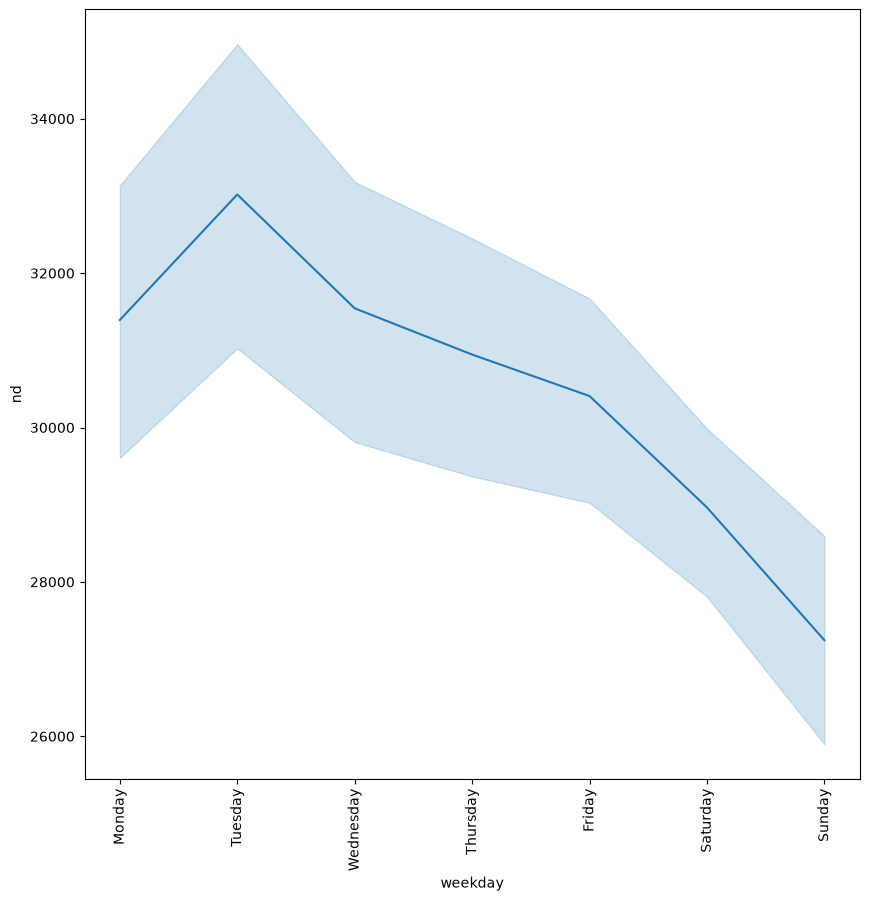

In [131]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# One box per weekday, in calendar order
plt.figure(figsize=(10, 10))
sns.lineplot(x='timestamp', y='nd', data=one_week,  palette='pastel')
plt.xticks(rotation=90)
plt.show()

plt.figure(figsize=(10, 10))
sns.lineplot(x='weekday', y='nd', data=one_week,  palette='pastel')
plt.xticks(rotation=90)
plt.show()

## 5. EDA summary

**Data:** NESO historic demand, 2018–2023. 105,168 half-hours (6 × 17,520, plus 48 for the 2020 leap day). All values in MW.


### Data quality
| Check | Result |
| --- | --- |
| Rows per year | 17,520 per year; 17,568 in 2020 (leap year). Complete. |
| Half-hours per date | 48 on every date except 12 clock-change days (46 in March, 50 in October). No missing half-hours. |
| Timestamp | Built in GMT (+30 minutes per row), so clock changes don't break the timeline. UK clock time is used only for time-of-day and weekday plots. |
| Duplicates | None (no repeated date + period). |
| Blank cells | Only in columns that didn't exist in some files: scottish_transfer (2023 only); nsl, eleclink, viking, greenlink (missing in 2018). |
| Hidden missing values | 3 half-hours in 2018 where england_wales_demand = 0. Recording errors; ND is normal at those times. |
| Impossible values | None in ND (range 13,367–49,807 MW). |


### Patterns in ND
| Pattern | Size (gap between medians) | Shape |
| --- | --- | --- |
| Time of day | about 13,000 MW | Lowest about 04:00, rises 05:30–09:00, flat during the day, peaks 17:30–18:30 |
| Month (season) | about 10,000 MW | Highest in January, lowest in June |
| Year (trend) | about 4,400 MW over 6 years | Downward; dips in 2020, partly recovers in 2021 |
| Day of week | see the weekday notes | Weekends expected to be lower |

- ND is right-skewed and has two peaks (night and day). Both come from mixing times of day and seasons, so **no transform is needed**. The detector removes these patterns, and the leftovers (residuals) get checked for normality later.


### What else affects ND
- **Embedded solar:** lowers ND (r = −0.54 at summer midday). Hidden in the full data by night-time zeros and season.
- **Embedded wind:** lowers ND (r = −0.23 at winter 18:00). Across all the data the sign is reversed by season (Simpson's paradox).
- **TSD and England & Wales:** near-copies of ND (r = 0.98–1.00). No new information.
- **Pump storage:** linked to ND only through timing (it pumps at night).
- **Not in the data:** temperature (probably the biggest missing driver) and holidays. Because of this, cold snaps and holidays may get flagged as anomalies.


### Decisions for modelling
| Use | Why |
| --- | --- |
| `timestamp` (GMT) | Continuous timeline, no clock-change gaps |
| `nd` | The series being monitored for anomalies |
| Hour, weekday and month (UK clock time) | The daily, weekly and yearly patterns of "normal" |
| `embedded_solar_generation`, `embedded_wind_generation` | Each explains part of normal ND |


| Not used | Why |
| --- | --- |
| `tsd`, `england_wales_demand` | Versions of ND, so using them would show the model the answer. England & Wales is kept only as a data-quality check |
| Capacity columns | Estimates that get revised; already dropped |
| Interconnector flows, `scottish_transfer`, `non_bm_stor`, `pump_storage_pumping` | Supply and grid-balancing columns: they respond to demand rather than drive it, and several are missing or 0 for long stretches |



Final dataset for processing and modelling

In [138]:
df_merged['weekday'] = df_merged['weekday'].str.lower()

In [141]:
weekday_map = {'monday': 0,
               'tuesday' :1,
               'wednesday': 2,
               'thursday': 3,
               'friday': 4,
               'saturday': 5,
               'sunday': 6
               }
df_merged.weekday = df_merged.weekday.replace(weekday_map)

In [146]:
df_merged.weekday.unique() 
df_merged.weekday=df_merged.weekday.astype(int)
df_merged.dtypes

settlement_date                       datetime64[us]
settlement_period                              int64
nd                                             int64
tsd                                            int64
england_wales_demand                           int64
embedded_wind_generation                       int64
embedded_solar_generation                      int64
non_bm_stor                                    int64
pump_storage_pumping                           int64
scottish_transfer                            float64
ifa_flow                                       int64
ifa2_flow                                      int64
britned_flow                                   int64
moyle_flow                                     int64
east_west_flow                                 int64
nemo_flow                                      int64
nsl_flow                                     float64
eleclink_flow                                float64
viking_flow                                  f

In [148]:
time_dt = pd.to_datetime(df_merged['timestamp_raw'], format = 'mixed').dt

In [150]:
df_merged['half_hour_intervals'] = (time_dt.hour * 2) + (time_dt.minute // 30)
df_merged.dtypes

settlement_date                       datetime64[us]
settlement_period                              int64
nd                                             int64
tsd                                            int64
england_wales_demand                           int64
embedded_wind_generation                       int64
embedded_solar_generation                      int64
non_bm_stor                                    int64
pump_storage_pumping                           int64
scottish_transfer                            float64
ifa_flow                                       int64
ifa2_flow                                      int64
britned_flow                                   int64
moyle_flow                                     int64
east_west_flow                                 int64
nemo_flow                                      int64
nsl_flow                                     float64
eleclink_flow                                float64
viking_flow                                  f

In [151]:
# create modelling df:
df_modelling = df_merged[['nd', 'timestamp', 'embedded_solar_generation', 'embedded_wind_generation', 'year', 'month', 'weekday', 'half_hour_intervals']]

In [153]:
df_modelling.to_parquet('../data/modelling/df_modelling.parquet', engine = 'pyarrow', index = False)
